# Gambeta — Modèles prédictifs (Elo, Poisson, backtest)

**Question :** à partir des seuls résultats des matchs, peut-on mesurer la vraie force des clubs et prédire les matchs à venir ?

Ce notebook :
1. construit un **classement Elo** et règle ses paramètres par recherche sur grille ;
2. ajuste un **modèle de Poisson (Dixon-Coles)** : force d'attaque et de défense de chaque club ;
3. **teste honnêtement** les modèles : chaque journée de 2024-25 et 2025-26 est prédite avec les seuls matchs déjà joués (*walk-forward*), puis comparée à la réalité.

Le code des modèles est dans `gambeta_models.py` (pandas + numpy uniquement) ; `export_models.py` envoie les résultats vers le site.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gambeta_style as gs
from gambeta_data import load_matches, season_label
from gambeta_models import run_elo, tune_elo, fit_poisson, fit_rho, expected_goals, score_matrix, outcome_probs, backtest

gs.apply()
m = load_matches()
print(f"{len(m):,} matchs de saison régulière, {m['season'].nunique()} saisons, {m['league'].nunique()} championnats")

8,908 matchs de saison régulière, 5 saisons, 5 championnats


## 1. Classement Elo

Après chaque match, le vainqueur prend des points au perdant, d'autant plus que la victoire était inattendue (et un peu plus si l'écart de buts est large). Deux réglages : **K** (amplitude des mises à jour) et l'**avantage du terrain**. On teste 30 combinaisons et on garde celle dont les espérances de victoire sont les plus proches des résultats (erreur de Brier minimale), en ignorant la 1re saison qui sert à « chauffer » les notes.

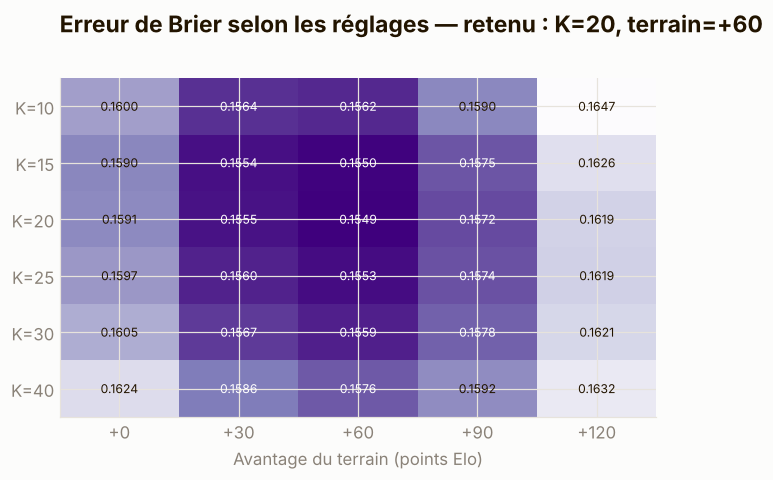

In [2]:
grid, best_k, best_home = tune_elo(m)
pivot = grid.pivot(index="k", columns="home", values="brier")
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(pivot.values, cmap="Purples_r", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), [f"+{c}" for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)), [f"K={k}" for k in pivot.index])
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.4f}", ha="center", va="center", fontsize=8,
                color="white" if pivot.values[i, j] < pivot.values.mean() else gs.INK)
ax.set_xlabel("Avantage du terrain (points Elo)")
ax.set_title(f"Erreur de Brier selon les réglages — retenu : K={best_k}, terrain=+{best_home}", loc="left")
plt.show()

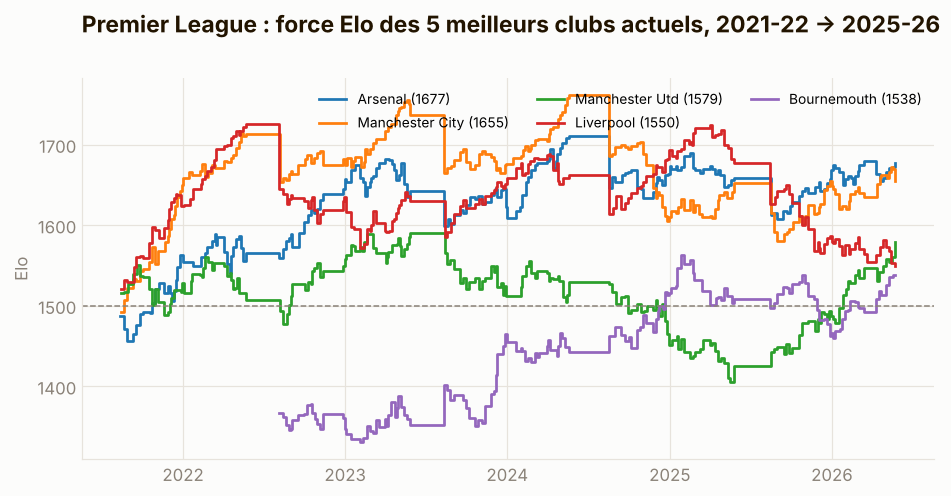

In [3]:
hist, pre = run_elo(m, best_k, best_home)
pl = hist[hist["league"] == "Premier League"]
top = pl[pl["season"] == "2526"].sort_values("date").groupby("team").tail(1).nlargest(5, "elo")["team"]
fig, ax = plt.subplots(figsize=(10, 4.5))
for team in top:
    s = pl[pl["team"] == team].sort_values("date")
    ax.step(s["date"], s["elo"], where="post", lw=1.8, label=f"{team} ({s['elo'].iloc[-1]:.0f})")
ax.axhline(1500, color=gs.MUTED, lw=1, ls="--")
ax.set_ylabel("Elo")
ax.set_title("Premier League : force Elo des 5 meilleurs clubs actuels, 2021-22 → 2025-26", loc="left")
ax.legend(frameon=False, ncol=3, fontsize=9)
plt.show()

## 2. Modèle de Poisson (Dixon-Coles)

$\log(\text{buts}_{A \to B}) = \mu + \text{domicile} + \text{attaque}_A - \text{défense}_B$

Ajusté par régression de Poisson pondérée (algorithme IRLS) :
- pondération temporelle : un match d'il y a 240 jours compte moitié moins ;
- pénalité *ridge* sur les forces, utile pour les promus (peu de matchs) ;
- correction de Dixon-Coles (paramètre ρ) sur les petits scores 0-0, 1-0, 0-1, 1-1, que la loi de Poisson sous-estime.

In [4]:
as_of = m["date"].max() + pd.Timedelta(days=1)
pl_m = m[m["league"] == "Premier League"]
model = fit_poisson(pl_m, as_of)
rho = fit_rho(pl_m[pl_m["date"] >= as_of - pd.Timedelta(days=365)], model)
teams_2526 = sorted(set(pl_m[pl_m.season == "2526"]["home_team"]))
strength = pd.DataFrame({
    "attaque": [model["att"][t] for t in teams_2526],
    "défense": [model["def"][t] for t in teams_2526],
}, index=teams_2526).sort_values("attaque", ascending=False)
print(f"Avantage du terrain : x{np.exp(model['home']):.2f} buts ; rho = {rho:.3f}")
strength.round(3).head(8)

Avantage du terrain : x1.20 buts ; rho = -0.140


,attaque,défense
Manchester City,0.413,0.409
Liverpool,0.331,0.104
Arsenal,0.331,0.598
Manchester Utd,0.221,0.113
Newcastle,0.186,0.047
Aston Villa,0.161,0.099
Chelsea,0.144,0.083
Brentford,0.130,0.067


Arsenal - Manchester City : buts attendus 1.40 - 1.05
Victoire Arsenal 43% · nul 30% · victoire City 26%


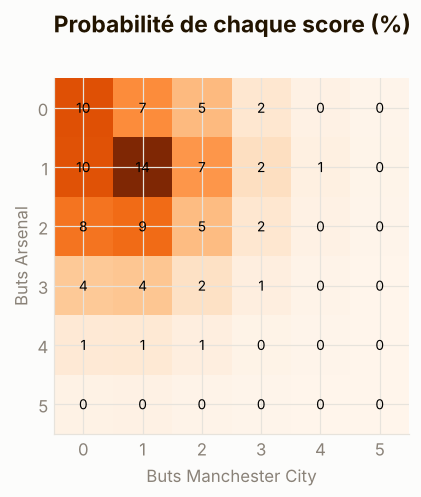

In [5]:
lh, la = expected_goals(model, "Arsenal", "Manchester City")
sm = score_matrix(lh, la, rho)
ph, pd_, pa = outcome_probs(sm)
print(f"Arsenal - Manchester City : buts attendus {lh:.2f} - {la:.2f}")
print(f"Victoire Arsenal {ph:.0%} · nul {pd_:.0%} · victoire City {pa:.0%}")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(sm[:6, :6], cmap="Oranges")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{sm[i, j]*100:.0f}", ha="center", va="center", fontsize=9)
ax.set_xlabel("Buts Manchester City"); ax.set_ylabel("Buts Arsenal")
ax.set_title("Probabilité de chaque score (%)", loc="left")
plt.show()

## 3. Le vrai test : backtest *walk-forward*

Chaque journée de 2024-25 et 2025-26 est prédite par un modèle qui n'a vu **que** les matchs déjà joués. Trois modèles comparés :
- **Poisson (Dixon-Coles)** ;
- **Elo** (espérance Elo + taux de nuls habituel) ;
- **Référence naïve** : toujours les fréquences habituelles domicile / nul / extérieur.

Métriques : *log loss* (pénalise les erreurs commises avec assurance), score de Brier, précision (issue la plus probable = issue réelle). Plus bas = mieux pour les deux premières.

In [6]:
results, calib, preds = backtest(m, elo_k=best_k, elo_home=best_home, rho=-0.086)
results.round(3)

,season,model,log_loss,brier,accuracy,n
0,Toutes,Poisson (Dixon-Coles),0.991,0.591,0.522,3504
1,Toutes,Elo,1.008,0.597,0.521,3504
2,Toutes,Référence naïve,1.076,0.651,0.430,3504
3,2425,Poisson (Dixon-Coles),0.984,0.587,0.529,1752
4,2425,Elo,0.998,0.590,0.531,1752
5,2425,Référence naïve,1.079,0.654,0.420,1752
6,2526,Poisson (Dixon-Coles),0.997,0.595,0.516,1752
7,2526,Elo,1.019,0.605,0.512,1752
8,2526,Référence naïve,1.073,0.649,0.440,1752


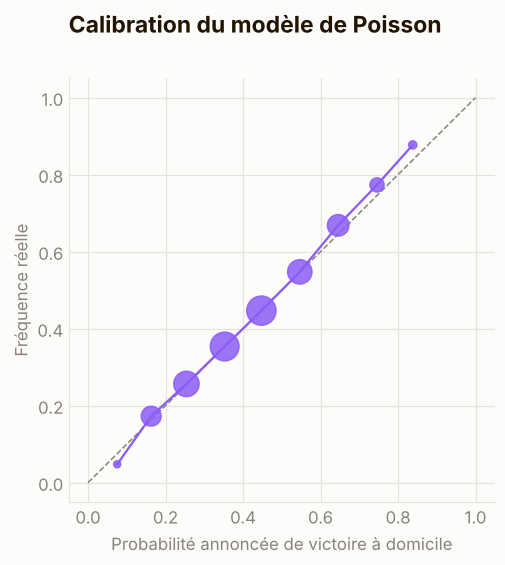

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], ls="--", color=gs.MUTED, lw=1)
ax.scatter(calib["predicted"], calib["observed"], s=calib["n"] / 2, color="#8b5cf6", alpha=0.85, zorder=3)
ax.plot(calib["predicted"], calib["observed"], color="#8b5cf6", lw=1.5)
ax.set_xlabel("Probabilité annoncée de victoire à domicile")
ax.set_ylabel("Fréquence réelle")
ax.set_title("Calibration du modèle de Poisson", loc="left")
plt.show()

## Ce qu'il faut retenir

- Le modèle de Poisson bat les deux références sur les 3 504 matchs prédits à l'aveugle (log loss ≈ 0,99 contre 1,01 pour l'Elo et 1,08 pour la référence naïve).
- Il trouve la bonne issue environ **une fois sur deux** : le football, avec peu de buts, reste très aléatoire.
- Il est **bien calibré** : quand il annonce 35 % de victoire à domicile, cela arrive environ 35 % du temps — c'est ce qui rend ses probabilités utilisables.
- Limites : aucun xG ni composition d'équipe dans le modèle (seulement les scores) ; les forces de deux championnats ne sont pas comparables entre elles.